## 1. Import libraries

In [1]:
# install the export stuff
!pip -q install onnx onnxscript onnxruntime

# the big toolbox
import random                      # for random numbers
import json                        # for saving the scaler for the website
import numpy as np                 # math with lists of numbers
import pandas as pd                # excel but for python
import matplotlib.pyplot as plt    # makes pictures
import torch                       # PyTorch = the brain builder
from torch import nn               # nn = neural network parts
from torch.utils.data import TensorDataset, DataLoader   # hands data to the brain in small bites

from sklearn.model_selection import train_test_split     # cuts data into study pile and exam pile
from sklearn.preprocessing import StandardScaler         # squishes numbers to the same size

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

# use the fast GPU if we have one, otherwise just use the slow normal chip
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("We are using:", device)

We are using: cuda


## 2. Load the data and look at it

In [2]:
url = "https://archive.ics.uci.edu/ml/machine-learning-databases/auto-mpg/auto-mpg.data"
column_names = ["mpg", "cylinders", "displacement", "horsepower", "weight",
                "acceleration", "model_year", "origin", "car_name"]

try:
    df = pd.read_csv(url, names=column_names, na_values="?", comment="\t",
                     sep=" ", skipinitialspace=True)
except Exception as e:
    print("UCI download failed, using seaborn's copy instead:", e)
    import seaborn as sns
    df = sns.load_dataset("mpg")
    df["origin"] = df["origin"].map({"usa": 1, "europe": 2, "japan": 3})   # words -> numbers

df = df.drop(columns=["car_name", "name"], errors="ignore")   # the car's name is a label, not a measurement

print(df.head())
print("Shape (rows, columns):", df.shape)
print("Missing values per column:")
print(df.isna().sum())                   # a few cars have a blank horsepower

df = df.dropna()                         # throw away cars with blanks
print("Shape after cleaning:", df.shape)
print(df.describe().round(2))

target_name = "mpg"                                              # what we want to guess
feature_names = [c for c in df.columns if c != target_name]      # the 7 clues
print("Clues:", feature_names)

X = df[feature_names].to_numpy(dtype=np.float32)
y = df[target_name].to_numpy(dtype=np.float32).reshape(-1, 1)

    mpg  cylinders  displacement  horsepower  weight  acceleration  \
0  18.0          8         307.0       130.0  3504.0          12.0   
1  15.0          8         350.0       165.0  3693.0          11.5   
2  18.0          8         318.0       150.0  3436.0          11.0   
3  16.0          8         304.0       150.0  3433.0          12.0   
4  17.0          8         302.0       140.0  3449.0          10.5   

   model_year  origin  
0          70       1  
1          70       1  
2          70       1  
3          70       1  
4          70       1  
Shape (rows, columns): (398, 8)
Missing values per column:
mpg             0
cylinders       0
displacement    0
horsepower      6
weight          0
acceleration    0
model_year      0
origin          0
dtype: int64
Shape after cleaning: (392, 8)
          mpg  cylinders  displacement  horsepower   weight  acceleration  \
count  392.00     392.00        392.00      392.00   392.00        392.00   
mean    23.45       5.47        19

## 3. Split the data and scale it

In [3]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=SEED)

raw_test = X_test.copy()        # keep RAW rows for the website demo button
actual = y_test.ravel()         # the REAL mpg of the exam cars

# Scaler learns average + spread from the STUDY pile only
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train).astype("float32")
X_test = scaler.transform(X_test).astype("float32")

# MPG is around 23, brains learn faster when answers are near 0.
# We un-squish the guesses later to get real MPG back.
y_scaler = StandardScaler()
y_train = y_scaler.fit_transform(y_train).astype("float32")

print("Train:", len(X_train), " Test:", len(X_test), " Features:", X_train.shape[1])

# feed the brain 32 cars at a time
loader = DataLoader(TensorDataset(torch.tensor(X_train), torch.tensor(y_train)),
                    batch_size=32, shuffle=True)

Xte = torch.tensor(X_test).to(device)

Train: 313  Test: 79  Features: 7


## 4. Build three PyTorch models

In [4]:
# This is the brain. It is just a stack of Linear + ReLU.
class Net(nn.Module):
    def __init__(self, widths, n_outputs=1):
        super().__init__()
        layers = []
        how_many_inputs = X_train.shape[1]

        for w in widths:
            layers.append(nn.Linear(how_many_inputs, w))
            layers.append(nn.ReLU())
            how_many_inputs = w

        layers.append(nn.Linear(how_many_inputs, n_outputs))
        self.net = nn.Sequential(*layers)

    def forward(self, x):
        return self.net(x)

# three brains: small, medium, big. we will see which one wins.
configs = {
    "Small [16]": [16],
    "Medium [64,32]": [64, 32],
    "Large [128,64,32]": [128, 64, 32],
}

In [5]:
# The brain goes to school
def train(widths, epochs=300):
    model = Net(widths).to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=0.001, weight_decay=1e-5)
    loss_function = nn.MSELoss()     # "how far off was the guess, squared"
    history = []

    for epoch in range(epochs):      # 1 epoch = seeing every car once
        model.train()
        total_loss = 0

        for xb, yb in loader:
            xb = xb.to(device)
            yb = yb.to(device)

            optimizer.zero_grad()              # erase old mistakes
            guess = model(xb)                  # brain guesses
            loss = loss_function(guess, yb)    # how wrong?
            loss.backward()                    # who to blame
            optimizer.step()                   # fix the brain a tiny bit

            total_loss += loss.item() * len(xb)

        history.append(total_loss / len(loader.dataset))

    return model, history

## 5. Train all three and compare (R2 is the main score)

In [6]:
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

models = {}
histories = {}
rows = []

for name, widths in configs.items():
    print("Training", name, "...")
    model, hist = train(widths)
    model.eval()                      # exam mode, no learning

    with torch.no_grad():
        scaled_guess = model(Xte).cpu().numpy()
    predicted = y_scaler.inverse_transform(scaled_guess).ravel()   # un-squish -> real MPG

    models[name] = model
    histories[name] = hist

    rows.append({
        "Model": name,
        "R2": r2_score(actual, predicted),                        # 1.0 = perfect, 0 = as dumb as guessing the average
        "MAE (mpg)": mean_absolute_error(actual, predicted),      # average miss. 2.0 means off by 2 mpg
        "RMSE (mpg)": np.sqrt(mean_squared_error(actual, predicted)),   # like MAE but hates big misses
    })

results = pd.DataFrame(rows).sort_values("R2", ascending=False)
print(results.round(3))

best_name = results.iloc[0]["Model"]
best = models[best_name]
print("WINNER:", best_name)

Training Small [16] ...
Training Medium [64,32] ...
Training Large [128,64,32] ...
               Model     R2  MAE (mpg)  RMSE (mpg)
0         Small [16]  0.875      1.826       2.528
1     Medium [64,32]  0.861      1.990       2.667
2  Large [128,64,32]  0.815      2.151       3.074
WINNER: Small [16]


## 6. Pictures

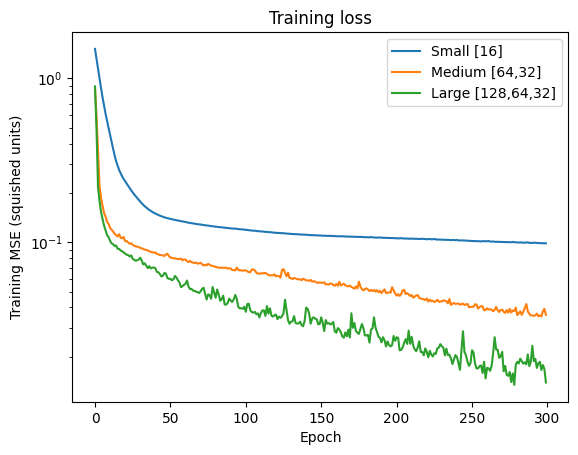

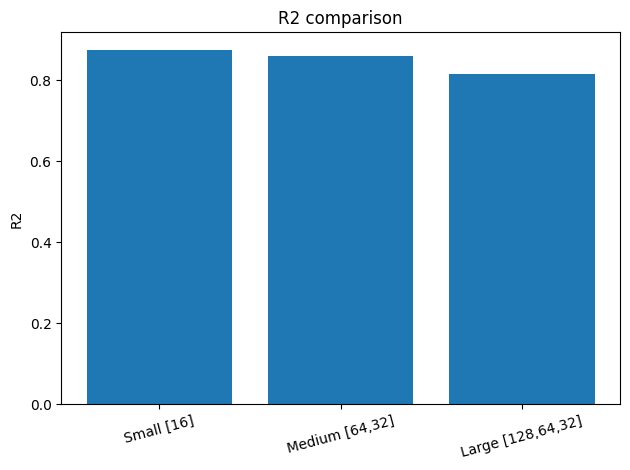

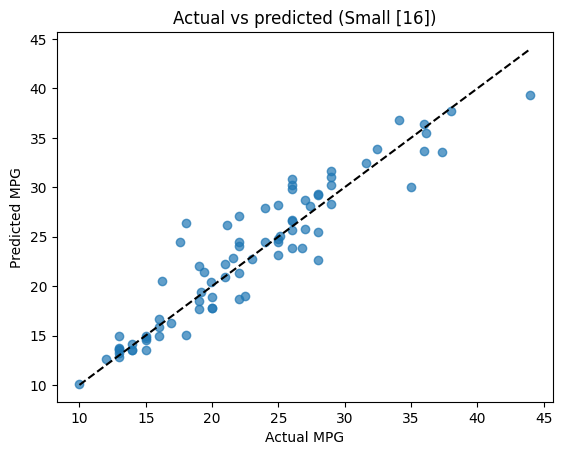

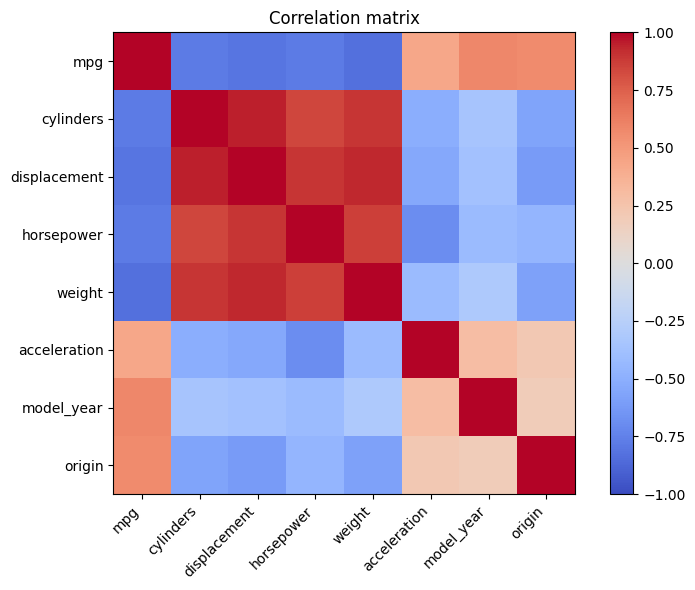

weight         -0.832
displacement   -0.805
horsepower     -0.778
cylinders      -0.778
model_year      0.581
origin          0.565
acceleration    0.423
Name: mpg, dtype: float64


In [7]:
# Picture 1: loss going down = brain is learning
for name, hist in histories.items():
    plt.plot(hist, label=name)
plt.xlabel("Epoch"); plt.ylabel("Training MSE (squished units)"); plt.title("Training loss")
plt.yscale("log"); plt.legend(); plt.show()

# Picture 2: R2 bar chart (taller = better)
plt.bar(results["Model"], results["R2"])
plt.ylabel("R2"); plt.title("R2 comparison"); plt.xticks(rotation=15)
plt.tight_layout(); plt.show()

# Picture 3: actual vs predicted. Dots near the dashed line = good guesses.
with torch.no_grad():
    pred = y_scaler.inverse_transform(best(Xte).cpu().numpy()).ravel()
plt.scatter(actual, pred, alpha=0.7)
low = min(actual.min(), pred.min())
high = max(actual.max(), pred.max())
plt.plot([low, high], [low, high], "k--")
plt.xlabel("Actual MPG"); plt.ylabel("Predicted MPG"); plt.title("Actual vs predicted (" + best_name + ")")
plt.show()

# Picture 4: correlation matrix (red = move together, blue = move opposite)
corr = df.corr()
plt.figure(figsize=(8, 6))
plt.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)
plt.colorbar()
plt.xticks(range(len(corr)), corr.columns, rotation=45, ha="right")
plt.yticks(range(len(corr)), corr.columns)
plt.title("Correlation matrix")
plt.tight_layout(); plt.show()

# Which clue matters most for MPG? (negative = heavier/bigger means fewer miles per gallon)
print(corr[target_name].drop(target_name).sort_values(key=abs, ascending=False).round(3))

## 7. Export the winner to ONNX (for the website)

In [8]:
best = best.cpu().eval()                       # ONNX export wants the CPU
dummy = torch.randn(1, X_train.shape[1])       # a fake car so ONNX knows the shape

torch.onnx.export(best, dummy, "regression_model.onnx",
                  input_names=["features"],       # website MUST use this name
                  output_names=["prediction"],    # and this one
                  opset_version=17, dynamo=False)

# the website needs BOTH squishing rules, plus one real example car for a demo button.
with open("regression_scaler.json", "w") as f:
    json.dump({"names": feature_names, "target": "Gas mileage", "unit": "MPG",
               "mean": scaler.mean_.tolist(), "scale": scaler.scale_.tolist(),
               "target_mean": float(y_scaler.mean_[0]), "target_scale": float(y_scaler.scale_[0]),
               "example": raw_test[0].tolist(),
               "example_actual": float(actual[0])}, f)

# SANITY CHECK: ONNX should give the same answers as PyTorch
import onnx, onnxruntime as ort
onnx.checker.check_model(onnx.load("regression_model.onnx"))
session = ort.InferenceSession("regression_model.onnx")
onnx_out = np.vstack([session.run(None, {"features": X_test[i:i+1]})[0] for i in range(5)])
with torch.no_grad():
    torch_out = best(torch.tensor(X_test[:5])).numpy()
print("PyTorch :", torch_out.ravel())
print("ONNX    :", onnx_out.ravel())
print("Same? ->", np.allclose(torch_out, onnx_out, atol=1e-3))

/tmp/ipykernel_816/650794101.py:4: DeprecationWarning: You are using the legacy TorchScript-based ONNX export. Starting in PyTorch 2.9, the new torch.export-based ONNX exporter has become the default. Learn more about the new export logic: https://docs.pytorch.org/docs/stable/onnx_export.html. For exporting control flow: https://pytorch.org/tutorials/beginner/onnx/export_control_flow_model_to_onnx_tutorial.html
  torch.onnx.export(best, dummy, "regression_model.onnx",


PyTorch : [ 0.38601652 -0.09374974  1.5017768   0.03465272  0.63910854]
ONNX    : [ 0.38601652 -0.09374973  1.5017769   0.03465272  0.6391085 ]
Same? -> True


In [9]:
# download the files (Colab only; elsewhere it just says so)
try:
    from google.colab import files
    files.download("regression_model.onnx")
    files.download("regression_scaler.json")
except ImportError:
    print("Not in Colab. The files are sitting in this folder already.")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>